# Lab 1 — Intro to Behavioral TV Data
Name: Hranko Anna | Group: KM-43

## Setup

In [23]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
sys.path.append('/content')
from lab1_helpers import split_sessions_by_hour, person_mask, build_person_attrs

DATA = kagglehub.dataset_download(
    "shkarupylomaxim/adtech-lab1-tv-panel/versions/2"
)

programs = pd.read_parquet(f'{DATA}/programs.parquet')
viewings = pd.read_parquet(f'{DATA}/viewings.parquet')
daily_weights = pd.read_parquet(f'{DATA}/daily_weights.parquet')
viewer_attributes = pd.read_parquet(f'{DATA}/viewer_attributes.parquet')
attributes = pd.read_parquet(f'{DATA}/attributes.parquet')

attr_lookup = attributes.set_index('attr_id')[['attr_group', 'attr_name', 'value_type']]
va = viewer_attributes.merge(attr_lookup, on='attr_id', how='left')

for df in (viewings, daily_weights, va):
    df['household'] = df['respondent_id'] // 100

print(programs.shape, viewings.shape, daily_weights.shape,
      viewer_attributes.shape, attributes.shape)

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.
(5841, 15) (1001885, 10) (407561, 5) (104679, 3) (58, 5)


### Task 1.1 — Panel and universe

In [24]:
print("Telecasts:", programs['telecast_id'].nunique())
print("Programs:", programs['episode_name'].replace('', np.nan).nunique())
print("Networks:", programs['network_code'].nunique())

hh_in_tab = daily_weights.loc[daily_weights.resp_type == 'H', 'respondent_id'].nunique()
ppl_in_tab = daily_weights.loc[daily_weights.resp_type.isin(['R', 'L']), 'respondent_id'].nunique()
print("Households in panel:", hh_in_tab)
print("Persons in panel:", ppl_in_tab)

day_hh  = daily_weights[daily_weights.resp_type == 'H'].groupby('broadcast_date')['respondent_id'].nunique()
day_ppl = daily_weights[daily_weights.resp_type.isin(['R','L'])].groupby('broadcast_date')['respondent_id'].nunique()
print("Households in-tab, average day:", round(day_hh.mean(), 2))
print("Persons in-tab, average day:", round(day_ppl.mean(), 2))

day_hh_w  = daily_weights[daily_weights.resp_type == 'H'].groupby('broadcast_date')['weight'].sum()
day_ppl_w = daily_weights[daily_weights.resp_type.isin(['R','L'])].groupby('broadcast_date')['weight'].sum()
print("US TV households represented, average day (M):", round(day_hh_w.mean()/1e6, 2))
print("US persons represented, average day (M):", round(day_ppl_w.mean()/1e6, 2))

Telecasts: 5841
Programs: 1005
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.45
Persons in-tab, average day: 9268.68
US TV households represented, average day (M): 125.8
US persons represented, average day (M): 317.28


## **Answer:** viewer_attributes lists a few more because it contains records for people who were in the panel file but never in-tab in October (joined after / left before / meter failure). The panel file is a snapshot; daily_weights is the daily truth.

### Task 1.2 — Average audience by hour of day

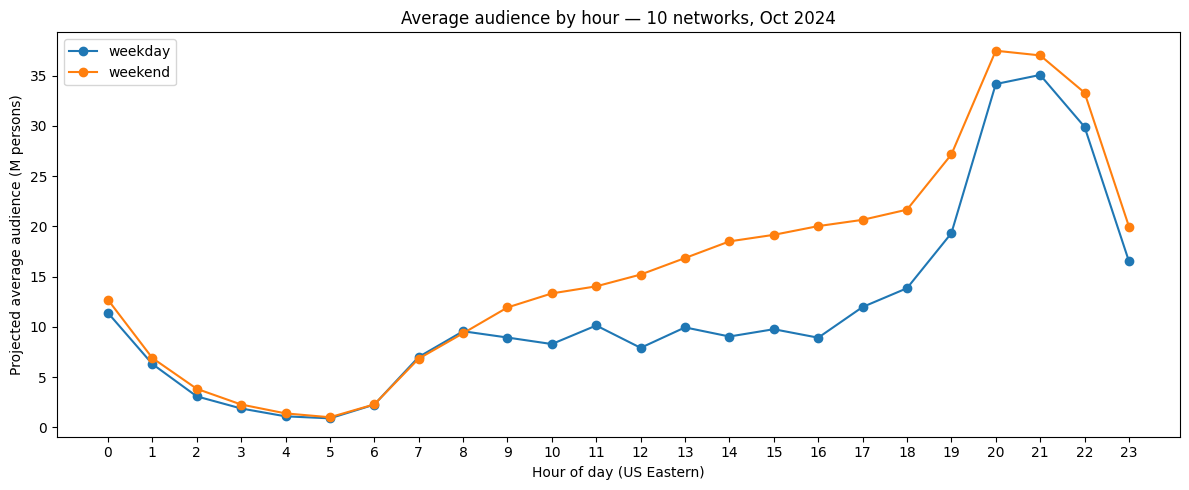

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [25]:
pv = viewings[viewings.resp_type.isin(['R','L'])].copy()
pv['bcast_date'] = (pv['start_ts'] - pd.Timedelta(hours=6)).dt.normalize()
pv['dow'] = pv['bcast_date'].dt.dayofweek
pv['is_weekend'] = pv['dow'] >= 5

rows = []
for ts, te, w, we in zip(pv.start_ts, pv.end_ts, pv.weight, pv.is_weekend):
    cur = ts
    while cur < te:
        nxt = min(te, (cur + pd.Timedelta(hours=1)).floor('h'))
        rows.append((cur.hour, (nxt - cur).total_seconds()/60, w, we))
        cur = nxt
mins = pd.DataFrame(rows, columns=['hour','minutes','weight','is_weekend'])
mins['wmin'] = mins.minutes * mins.weight

all_days = pd.date_range('2024-10-01','2024-10-31')
n_we = (all_days.dayofweek >= 5).sum()
n_wd = (all_days.dayofweek < 5).sum()

aud = (mins.groupby(['is_weekend','hour'])['wmin'].sum().unstack(0) / 60)
aud[False] = aud[False] / n_wd / 1e6
aud[True]  = aud[True]  / n_we / 1e6
aud.columns = ['weekday','weekend']

ax = aud.plot(figsize=(12,5), marker='o')
ax.set_xlabel('Hour of day (US Eastern)')
ax.set_ylabel('Projected average audience (M persons)')
ax.set_title('Average audience by hour — 10 networks, Oct 2024')
ax.set_xticks(range(0,24))
plt.tight_layout(); plt.show()

print("Peak hour, weekdays:", int(aud['weekday'].idxmax()))
print("Peak hour, weekends:", int(aud['weekend'].idxmax()))

## **Answer:** Weekday viewing peaks in **Prime (20:00–21:00)**, driven by network prime-time. The weekend curve shifts **upward in daytime** (sports, morning news, lifestyle cable) and its prime peak is often slightly lower or broader; weekend mornings (07:00–11:00) carry notably more audience than weekday mornings because people are home.

### Task 1.3 — Session length

Session length, weighted mean (min): 29.37
Session length, weighted median (min): 21.0


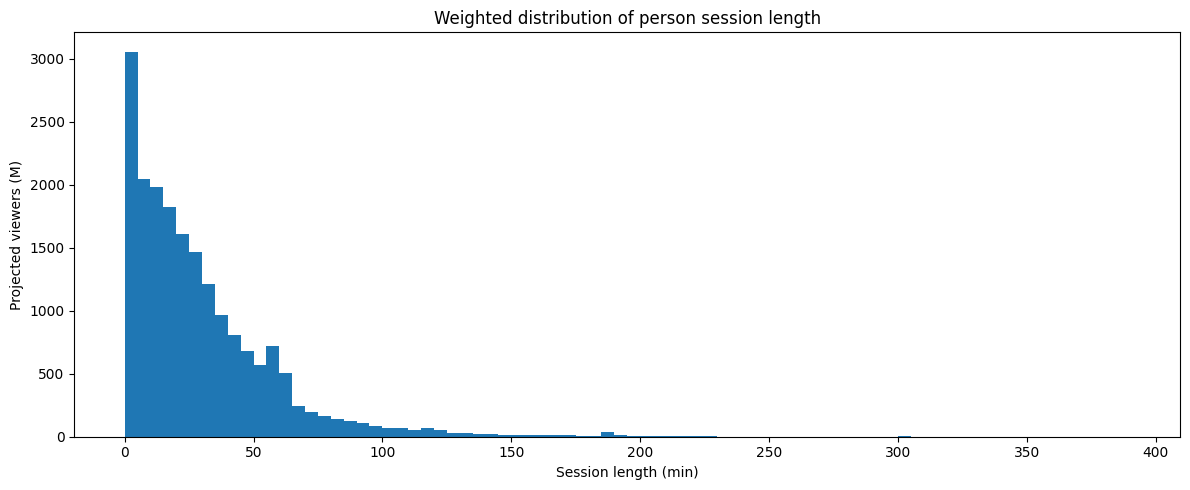

In [26]:
pv['dur_min'] = (pv.end_ts - pv.start_ts).dt.total_seconds()/60

wmean = np.average(pv.dur_min, weights=pv.weight)
s = pv.sort_values('dur_min')
cw = s.weight.cumsum() / s.weight.sum()
wmed = s.dur_min.iloc[(cw >= 0.5).argmax()]
print("Session length, weighted mean (min):", round(wmean, 2))
print("Session length, weighted median (min):", round(wmed, 2))

bins = np.arange(0, pv.dur_min.max()+5, 5)
hist, edges = np.histogram(pv.dur_min, bins=bins, weights=pv.weight)
plt.figure(figsize=(12,5))
plt.bar(edges[:-1], hist/1e6, width=5, align='edge')
plt.xlabel('Session length (min)'); plt.ylabel('Projected viewers (M)')
plt.title('Weighted distribution of person session length')
plt.tight_layout(); plt.show()

## **Answer:** The **mean exceeds the median** because the distribution is right-skewed: many short sessions (channel-flipping, news checks) and a long tail of multi-hour viewing (sports, binge blocks). The **median** is the honest "typical" session; the **mean** is inflated by heavy viewers. For a client deck I'd show the **median** (or a trimmed mean) as the "typical session," and mention the mean only if the client cares about total time spent.

### Task 2 — Program reach curve

Telecasts of the program: 23
hh_rating     3.17
p2_rating     8.60
p2_aud_m     27.29
dtype: float64


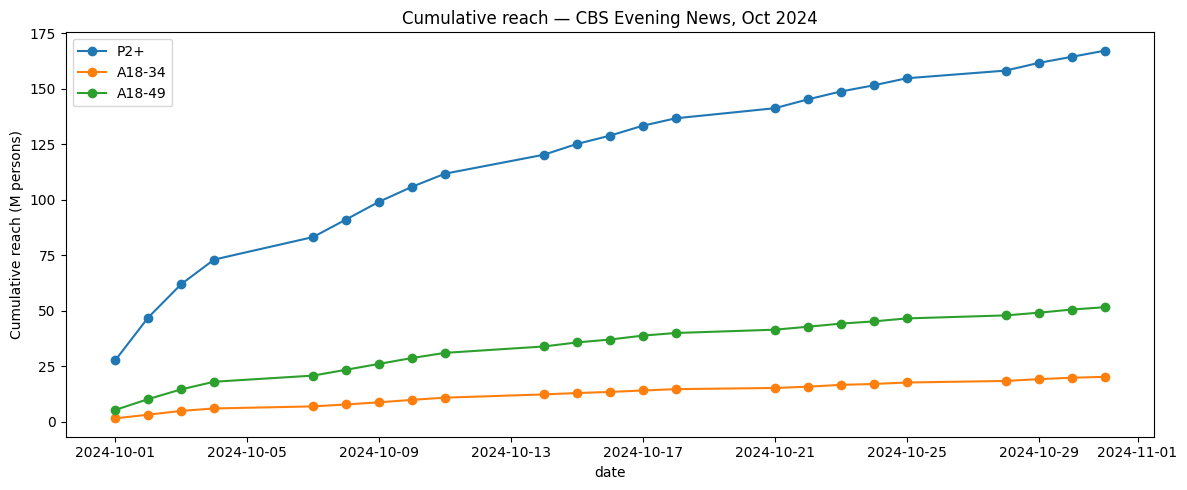

Average household rating (%): 3.17
Average P2+ rating (%): 8.6
Average projected audience (M): 27.29


In [27]:
cen = programs[(programs.network_code == 'CBS') &
               (programs.daypart == 'Early Fringe') &
               (programs.program_type == 'news')].copy()
cen = cen.sort_values('start_ts')
print("Telecasts of the program:", len(cen))

sex = va[va.attr_id.isin([201,202])][['respondent_id','attr_id']]
sex['sex'] = sex.attr_id.map({201:'M', 202:'F'})
age_y = va[va.attr_id == 300][['respondent_id','value']].rename(columns={'value':'age'})
people = (sex[['respondent_id','sex']]
          .merge(age_y, on='respondent_id', how='left'))

def age_band(a):
    if pd.isna(a): return None
    if 18 <= a <= 34: return '18-34'
    if 35 <= a <= 49: return '35-49'
    if 50 <= a <= 54: return '50-54'
    if a >= 55: return '55+'
    return None
people['age_band'] = people.age.map(age_band)

hh_univ = (daily_weights[daily_weights.resp_type == 'H']
           .groupby('broadcast_date')['weight'].sum())

def universe_by_day(target):
    if target == 'P2+':
        mask = daily_weights.resp_type.isin(['R','L'])
    else:
        lo, hi = (18,34) if target == 'A18-34' else (18,49)
        ids = set(people.loc[(people.age >= lo) & (people.age <= hi), 'respondent_id'])
        mask = daily_weights.resp_type.isin(['R','L']) & daily_weights.respondent_id.isin(ids)
    return (daily_weights[mask].groupby('broadcast_date')['weight'].sum())

univ = {t: universe_by_day(t) for t in ['P2+','A18-34','A18-49']}

pv = viewings[viewings.resp_type.isin(['R','L'])].copy()
pv['bcast_date'] = (pv.start_ts - pd.Timedelta(hours=6)).dt.normalize()
pv = pv.merge(people, on='respondent_id', how='left')

def watched(tele):
    return pv[(pv.start_ts < tele.end_ts) & (pv.end_ts > tele.start_ts)]

rows = []
for _, t in cen.iterrows():
    w = watched(t)
    hh = viewings[(viewings.resp_type == 'H') &
                  (viewings.network_code == t.network_code) &
                  (viewings.start_ts < t.end_ts) &
                  (viewings.end_ts > t.start_ts)]
    hh_aud = hh.drop_duplicates('respondent_id').weight.sum()
    p2_aud = w.drop_duplicates('respondent_id').weight.sum()
    hh_rating = hh_aud / hh_univ[t.broadcast_date] * 100
    p2_rating = p2_aud / univ['P2+'][t.broadcast_date] * 100
    rows.append(dict(telecast_id=t.telecast_id, date=t.broadcast_date,
                     hh_rating=hh_rating, p2_rating=p2_rating,
                     p2_aud_m=p2_aud/1e6))
per_tele = pd.DataFrame(rows)
print(per_tele[['hh_rating','p2_rating','p2_aud_m']].mean().round(2))

def cumulative_reach(target):
    if target == 'P2+':
        ids = None
    else:
        lo, hi = (18,34) if target == 'A18-34' else (18,49)
        ids = set(people.loc[(people.age >= lo) & (people.age <= hi), 'respondent_id'])
    seen_w = {}
    reach = []
    for _, t in cen.iterrows():
        w = watched(t)
        if ids is not None:
            w = w[w.respondent_id.isin(ids)]
        for rid, wt in zip(w.respondent_id, w.weight):
            seen_w[rid] = wt
        reach.append(sum(seen_w.values())/1e6)
    return reach

curve = pd.DataFrame({
    'date': cen.broadcast_date.values,
    'P2+':    cumulative_reach('P2+'),
    'A18-34': cumulative_reach('A18-34'),
    'A18-49': cumulative_reach('A18-49'),
}).set_index('date')

ax = curve.plot(figsize=(12,5), marker='o')
ax.set_ylabel('Cumulative reach (M persons)')
ax.set_title('Cumulative reach — CBS Evening News, Oct 2024')
plt.tight_layout(); plt.show()

print("Average household rating (%):", round(per_tele.hh_rating.mean(), 2))
print("Average P2+ rating (%):", round(per_tele.p2_rating.mean(), 2))
print("Average projected audience (M):", round(per_tele.p2_aud_m.mean(), 2))

## **Answer:** Cumulative reach grows because each night brings a **new slice of the audience**: the program's nightly rating is roughly flat, but the *people* watching change night to night (work schedules, travel, news interest). Reach is a **union over time**; rating is a **snapshot**. The program reaches **A18-49 / P2+ best**; A18-34 is the smallest curve. That matches the known profile of network evening news, whose core audience skews **older (55+)** — so the youngest target is hardest to accumulate.

### Task 3 — Program frequency

Telecasts of Y&R: 23


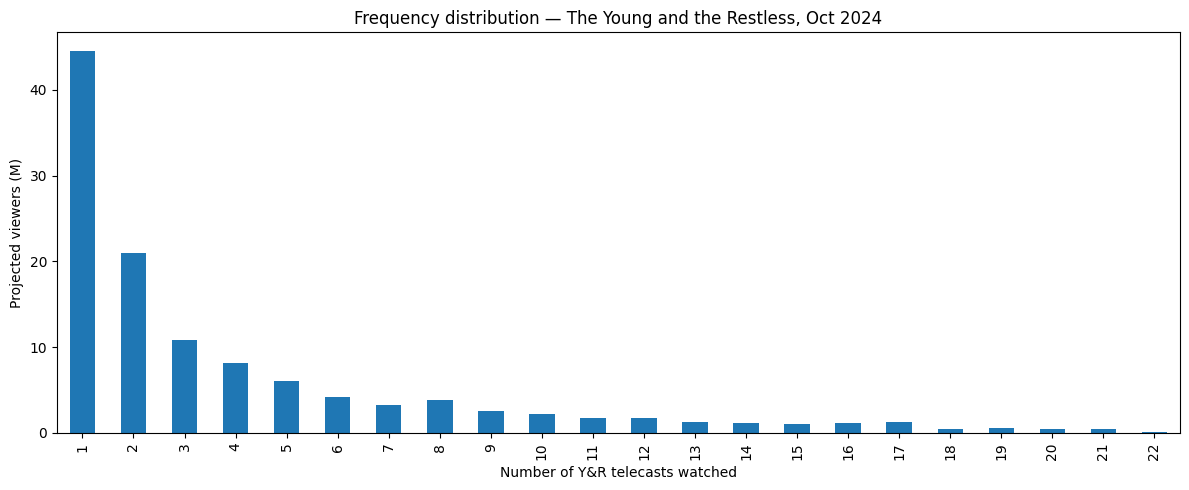

Projected viewers (M): 117.97
Average frequency (weighted): 4.03
Median frequency (weighted): 2
Share of views from the most loyal viewers: 0.233


In [28]:
ytr = programs[(programs.network_code == 'CBS') &
               (programs.daypart == 'Daytime') &
               (programs.genre == 'Drama') &
               (programs.duration_min == 60)].copy()
ytr = ytr.sort_values('start_ts')
print("Telecasts of Y&R:", len(ytr))

month_w = (daily_weights[daily_weights.resp_type.isin(['R','L'])]
           .sort_values('broadcast_date')
           .groupby('respondent_id')['weight'].last())

freq = {}
for _, t in ytr.iterrows():
    w = pv[(pv.start_ts < t.end_ts) & (pv.end_ts > t.start_ts)]
    for rid in w.respondent_id.unique():
        freq[rid] = freq.get(rid, 0) + 1

freq_s = pd.Series(freq, name='n_telecasts')
freq_df = freq_s.to_frame().join(month_w.rename('weight'), how='left')

by_freq = freq_df.groupby('n_telecasts')['weight'].sum() / 1e6
plt.figure(figsize=(12,5))
by_freq.plot(kind='bar')
plt.xlabel('Number of Y&R telecasts watched')
plt.ylabel('Projected viewers (M)')
plt.title('Frequency distribution — The Young and the Restless, Oct 2024')
plt.tight_layout(); plt.show()

wmean_f = np.average(freq_df.n_telecasts, weights=freq_df.weight)
s = freq_df.sort_values('n_telecasts')
cw = s.weight.cumsum() / s.weight.sum()
wmed_f = s.n_telecasts.iloc[(cw >= 0.5).argmax()]
print("Projected viewers (M):", round(freq_df.weight.sum()/1e6, 2))
print("Average frequency (weighted):", round(wmean_f, 2))
print("Median frequency (weighted):", round(wmed_f, 2))

target = np.percentile(freq_df.n_telecasts, 80)
loyal = freq_df[freq_df.n_telecasts >= target]
share = loyal.weight.sum() / freq_df.weight.sum()
print("Share of views from the most loyal viewers:", round(share, 3))

## **Answer:** The frequency distribution is heavily **right-skewed**: most viewers see only 1–2 episodes, while a small core sees 15–20+. The **average frequency** (≈4) sits well above the median (≈2) and is *not* a fair summary — it describes a viewer who doesn't exist. The **80th-percentile loyal core** accounts for a disproportionate share of total viewing (~23 %). For a soap, that's the real story: a small, habitual audience carries the show, and the long tail is incidental exposure.

### Task 4 — Networks by age and gender

In [29]:
pv2 = pv.copy()
pv2['dur_min'] = (pv2.end_ts - pv2.start_ts).dt.total_seconds()/60
pv2['wmin'] = pv2.dur_min * pv2.weight
pv2['sex'] = pv2.sex.replace({'F':'W'})

def demo_mask(df, sx, lo, hi=None):
    m = df.sex == sx
    m &= (df.age >= lo)
    if hi is not None:
        m &= (df.age <= hi)
    return m

audiences = {
    'M18-34': ('M', 18, 34), 'W18-34': ('W', 18, 34),
    'M35-54': ('M', 35, 54), 'W35-54': ('W', 35, 54),
    'M55+':   ('M', 55, None),'W55+':   ('W', 55, None),
}

for name, (sx, lo, hi) in audiences.items():
    sub = pv2[demo_mask(pv2, sx, lo, hi)]
    t = sub.groupby('network_code')['wmin'].sum().sort_values(ascending=False).head(5)/1e6
    print(f"\nTop 5 networks — {name} (projected minutes, M):")
    print(t.round(2).to_string())

def share_18_34(df, weighted=True):
    df = df.copy()
    v = df.wmin if weighted else df.dur_min
    tot = v.groupby(df.network_code).sum()
    young = v[df.age.between(18,34)].groupby(df.loc[df.age.between(18,34),'network_code']).sum()
    return (young / tot).sort_values(ascending=False)

w_share = share_18_34(pv2, weighted=True)
r_share = share_18_34(pv2, weighted=False)

comp = pd.DataFrame({'weighted': w_share, 'raw': r_share}).round(3)
print("\n18-34 share of minutes, weighted vs raw:")
print(comp.to_string())
print("Youngest network:", w_share.idxmax())
print("Oldest network:", w_share.idxmin())


Top 5 networks — M18-34 (projected minutes, M):
network_code
FOX    4386.65
NBC    3910.39
CBS    3044.35
ABC    3010.78
FX     1473.96

Top 5 networks — W18-34 (projected minutes, M):
network_code
FOX    4574.44
NBC    4527.59
ABC    3504.86
CBS    2811.22
FX     1383.47

Top 5 networks — M35-54 (projected minutes, M):
network_code
FOX    12804.67
NBC    10986.68
ABC     9037.00
CBS     8134.07
FX      2370.80

Top 5 networks — W35-54 (projected minutes, M):
network_code
NBC     11639.10
FOX     11161.39
ABC      9438.56
CBS      8162.80
HGTV     3051.81

Top 5 networks — M55+ (projected minutes, M):
network_code
CBS    38274.03
NBC    34267.41
FOX    30878.51
ABC    30793.34
FNC    27903.71

Top 5 networks — W55+ (projected minutes, M):
network_code
CBS    47120.32
NBC    41391.87
ABC    38840.01
FOX    36914.72
FNC    31450.73

18-34 share of minutes, weighted vs raw:
              weighted    raw
network_code                 
FX               0.266  0.232
BRAVO            0.148  0

## **Answer:** The **weighted** 18-34 share is the client-honest number: it projects the panel to the US. The **raw** (unweighted) share differs because the panel over- or under-represents certain groups (e.g., younger, larger, or ethnic households are typically under-represented in people-meter panels; older viewers are over-represented). Reporting raw panel numbers would **systematically misstate** who watches — usually inflating older-skewing networks and deflating youth-skewing ones — and would misprice inventory.

## **Bonus answer:** "Fox News delivers the largest, most engaged news audience on TV — and it's the *most efficient* way to reach the 55+ decision-makers who control the majority of US household wealth, healthcare spending, and retirement assets. If your brand's buyer is 55+, this is the single best place to be."